# Lab 20 — Cyber Threat Intelligence Analytics

*AI Cybersecurity Masterclass · Lab 20 · AI60secLab*

**Companion video:** [▶ Cyber Threat Intelligence in 60 Seconds](https://www.youtube.com/watch?v=JNR7B3pcemo&list=PLG4l6Ssi9A00) · [▶ Turn Security AI Into Decisions, Not Just Alerts](https://www.youtube.com/watch?v=O1Rr-mCNrWY&list=PLG4l6Ssi9A00)

**Research question:** What can we learn by analyzing ATT&CK relationships between adversary groups and techniques?

Instead of treating CTI as prose, we transform STIX relationships into structured evidence.

## Security foundation: the intelligence lifecycle

**Cyber threat intelligence (CTI)** is information about adversaries, analyzed so someone can make a decision. It follows a cycle: **direction** (what do we need to know?), **collection**, **processing**, **analysis**, **dissemination**, and **feedback**.

Two kinds of intelligence:
- **indicators of compromise (IOCs):** IPs, domains, file hashes. Cheap to share, quick to go stale;
- **tactics, techniques, and procedures (TTPs):** how adversaries operate. Slower to change, more useful for detection.

Sharing comes with rules. The **Traffic Light Protocol (TLP)** marks how far intelligence may travel: TLP:RED (named recipients only), AMBER, GREEN, and CLEAR (public).

In [ ]:
# Setup: works in Google Colab and locally. No uploads needed.
# In Colab this clones the course repo, which already includes the UNSW-NB15 data.
from pathlib import Path
import sys, os

REPO_URL = "https://github.com/Jacquelinepersha/ai-cybersecurity-public-labs.git"
REPO_NAME = "ai-cybersecurity-public-labs"

try:
    import google.colab  # noqa: F401
    if not Path(REPO_NAME).exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir(REPO_NAME)
except ImportError:
    pass

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

In [2]:
import matplotlib.pyplot as plt

from src.mitre_data import (
    ATTACK_ENTERPRISE_URL,
    load_remote_or_local,
)
from src.cti import (
    group_technique_edges,
    technique_usage_frequency,
    group_profile,
    tactic_coverage_for_group,
)

local_fallback = DATA_DIR / "enterprise-attack.json"

attack_bundle = load_remote_or_local(
    ATTACK_ENTERPRISE_URL,
    local_path=local_fallback,
)

edges = group_technique_edges(attack_bundle)
frequency = technique_usage_frequency(attack_bundle)

print("Group-technique relationships:", len(edges))
display(frequency.head(20))

Group-technique relationships: 4815


,technique_id,technique_name,group_count
157,T1105,Ingress Tool Transfer,90
214,T1204.002,Malicious File,87
90,T1059.001,PowerShell,86
420,T1588.002,Tool,84
364,T1566.001,Spearphishing Attachment,79
92,T1059.003,Windows Command Shell,73
55,T1036.005,Match Legitimate Resource Name or Location,66
297,T1547.001,Registry Run Keys / Startup Folder,59
130,T1082,System Information Discovery,59
116,T1071.001,Web Protocols,58


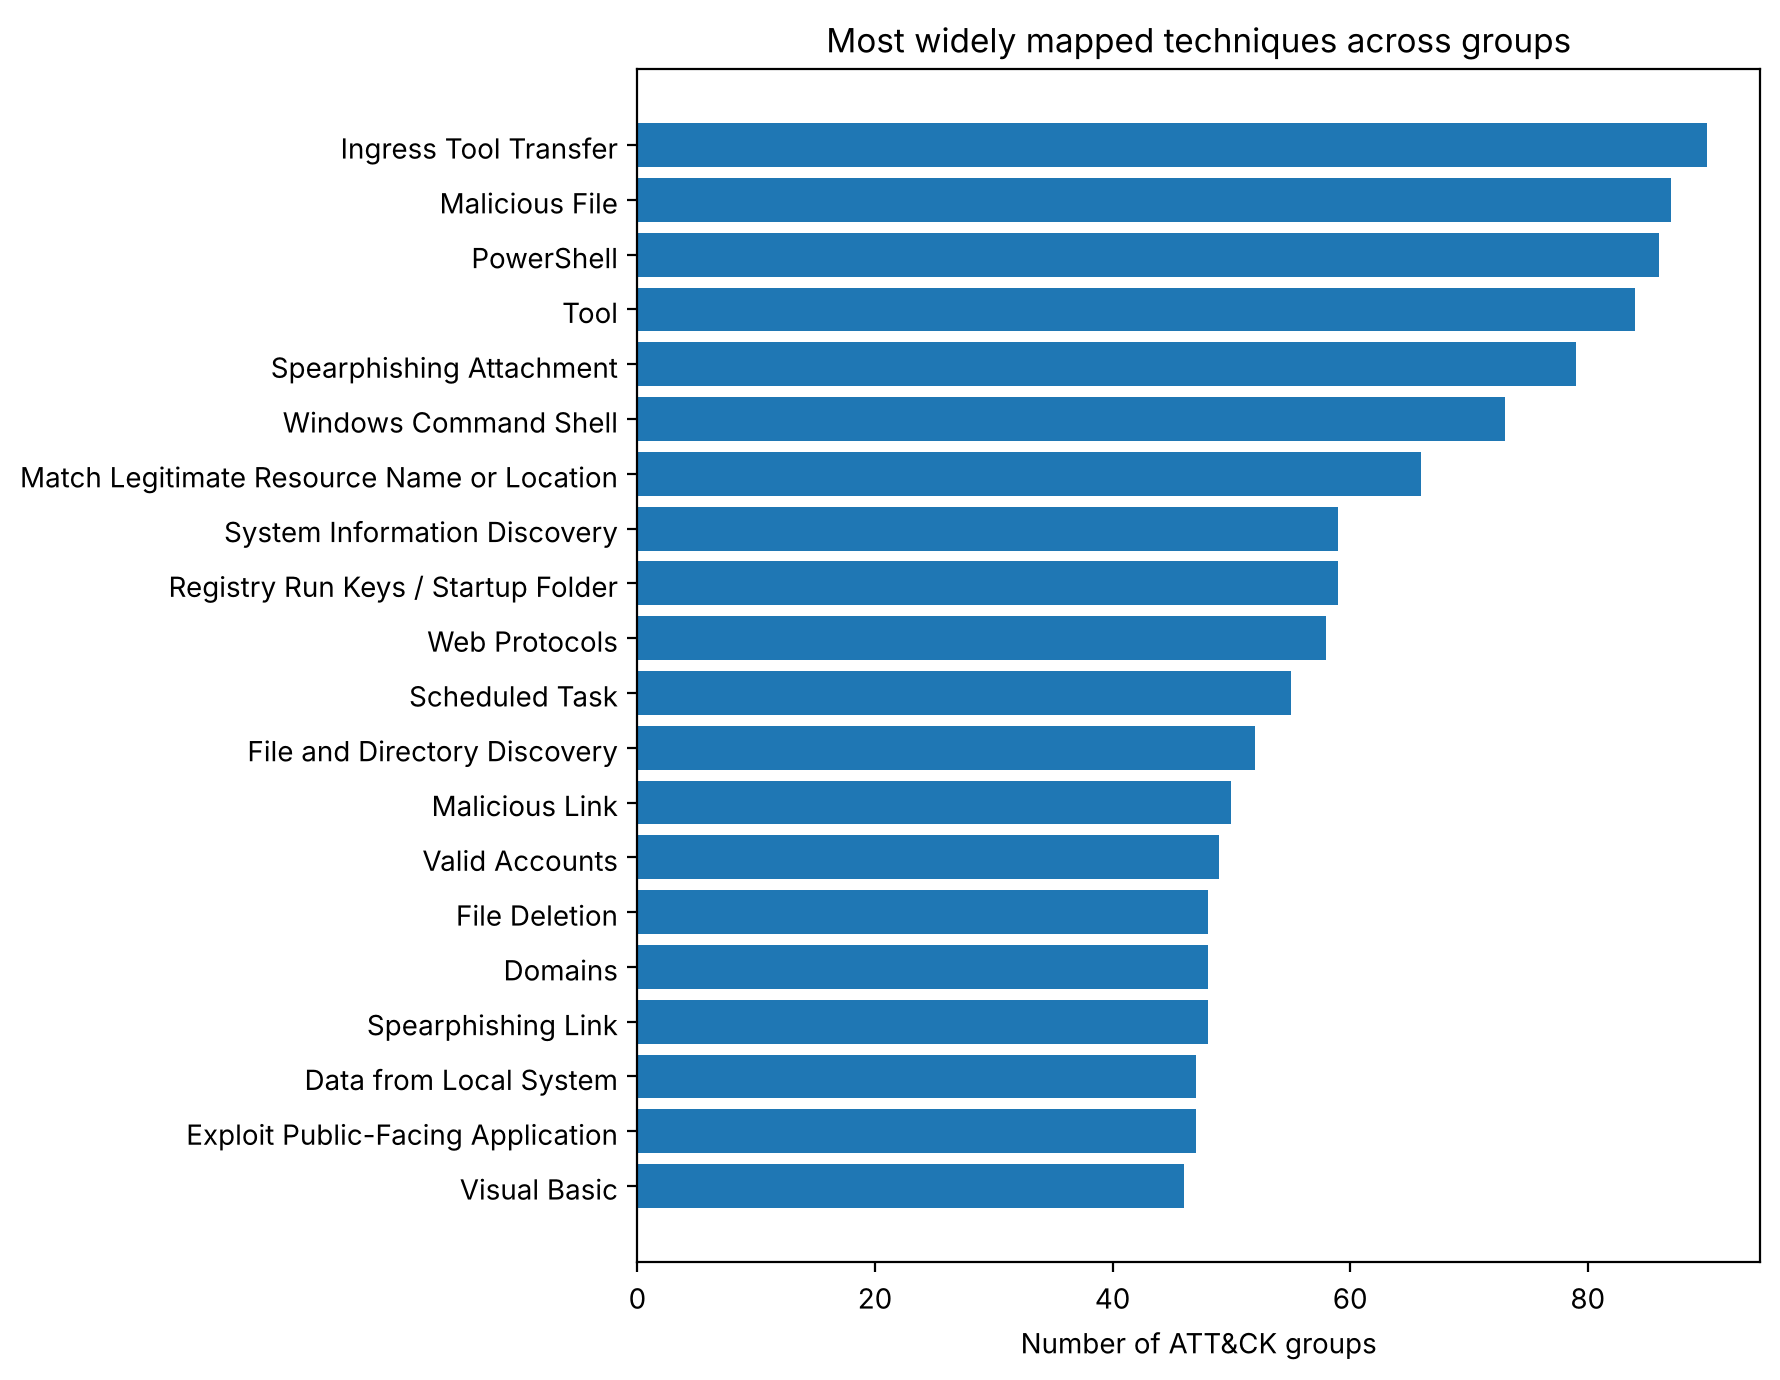

In [3]:
top = frequency.head(20).sort_values("group_count")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(
    top["technique_name"],
    top["group_count"],
)
ax.set_xlabel("Number of ATT&CK groups")
ax.set_title("Most widely mapped techniques across groups")
plt.tight_layout()
plt.show()

In [4]:
group_query = "APT29"

profile = group_profile(
    attack_bundle,
    group_query,
)

print("Mapped techniques:", len(profile))
display(profile.head(30))

coverage = tactic_coverage_for_group(profile)
display(coverage)

Mapped techniques: 66


,group_id,group_name,technique_id,technique_name,tactics
0,G0016,APT29,T1005,Data from Local System,collection
1,G0016,APT29,T1114.002,Remote Email Collection,collection
2,G0016,APT29,T1090.002,External Proxy,command-and-control
3,G0016,APT29,T1090.003,Multi-hop Proxy,command-and-control
4,G0016,APT29,T1090.004,Domain Fronting,command-and-control
5,G0016,APT29,T1105,Ingress Tool Transfer,command-and-control
6,G0016,APT29,T1568,Dynamic Resolution,command-and-control
7,G0016,APT29,T1573,Encrypted Channel,command-and-control
8,G0016,APT29,T1665,Hide Infrastructure,command-and-control
9,G0016,APT29,T1003.002,Security Account Manager,credential-access


,tactic,technique_count
8,persistence,15
9,privilege-escalation,13
12,stealth,10
5,execution,9
6,initial-access,9
2,credential-access,8
1,command-and-control,7
11,resource-development,6
3,defense-impairment,3
4,discovery,2


## Intelligence interpretation

- Which tactics have the largest mapped coverage for the selected group?
- Which techniques are common across many groups?
- What telemetry would be required to observe these behaviors?
- Why should ATT&CK mappings organize evidence rather than be treated as automatic attribution?

**Takeaway:** CTI becomes more useful when relationships are queryable and tied to observable evidence.

## From lab to SOC

Intelligence turns an alert into a decision: what happened, why it was flagged, what it might mean, how confident we are, and what to check next. Analyst feedback closes the loop by improving labels and future detections.

**Check yourself**
1. Why does an IP-address IOC go stale faster than a TTP?
2. What does TLP:AMBER allow you to do with a report?
3. Which of the five alert questions can flow data answer on its own?